In [3]:

# ==================================================
# IBM TELCO CUSTOMER CHURN ANALYSIS
# 1. IMPORT LIBRARIES
# ==================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [4]:
# ==================================================
# 2. LOAD DATASET
# ==================================================

df = pd.read_csv(r"C:\Users\MARLON_\Downloads\telco_customer_churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
# ==================================================
# 3. DATA EXPLORATION
# ==================================================

print("Dataset Shape:", df.shape)
print("\nColumn Names:", df.columns.tolist())

df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (7043, 21)

Column Names: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   Online

In [6]:
# ==================================================
# 4. DATA CLEANING
# ==================================================

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

df = df.dropna(subset=["TotalCharges"]).copy()
df = df.drop_duplicates(subset=["customerID"])

df["Churn_Flag"] = df["Churn"].map({"Yes": 1, "No": 0})

print("Cleaned Dataset Shape:", df.shape)

Cleaned Dataset Shape: (7032, 22)


In [7]:
# ==================================================
# 5. CUSTOMER CHURN AND RETENTION RATES
# ==================================================

total_customers = len(df)
churned_customers = df["Churn_Flag"].sum()
retained_customers = total_customers - churned_customers

churn_rate = churned_customers / total_customers * 100
retention_rate = retained_customers / total_customers * 100

print("Total Customers:", total_customers)
print("Churned Customers:", churned_customers)
print("Retained Customers:", retained_customers)
print(f"Churn Rate: {churn_rate:.2f}%")
print(f"Retention Rate: {retention_rate:.2f}%")

Total Customers: 7032
Churned Customers: 1869
Retained Customers: 5163
Churn Rate: 26.58%
Retention Rate: 73.42%


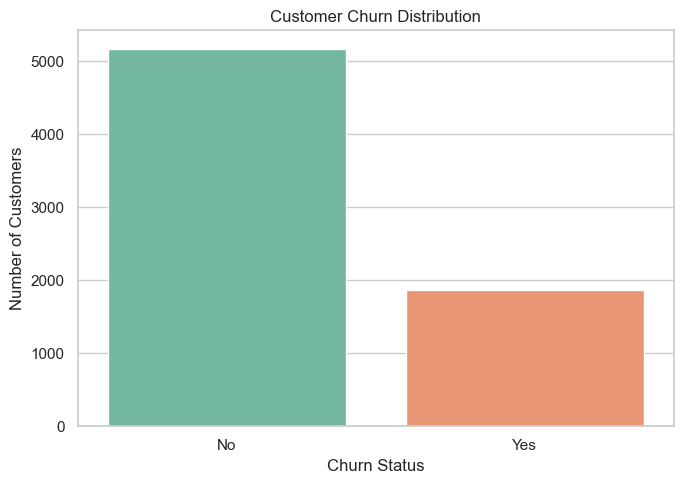

In [8]:
# ==================================================
# 6. CUSTOMER CHURN DISTRIBUTION
# ==================================================

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Churn",
    order=["No", "Yes"],
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

         Contract  Total_Customers  Churned_Customers  Churn_Rate
0  Month-to-month             3875               1655       42.71
1        One year             1472                166       11.28
2        Two year             1685                 48        2.85


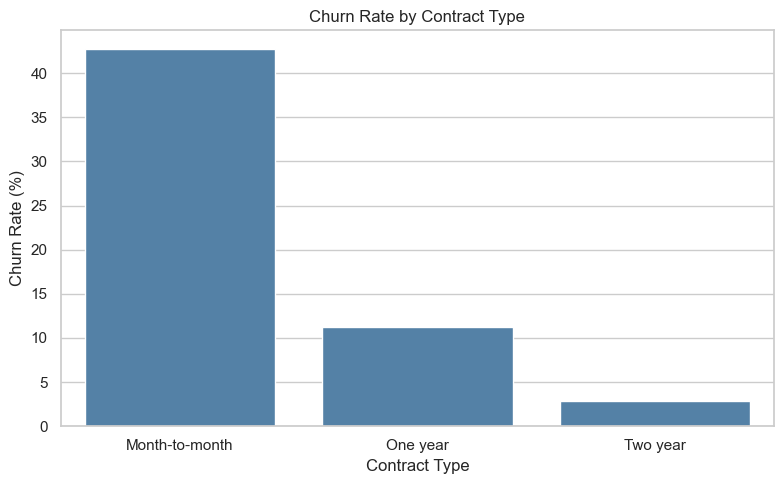

In [9]:
# ==================================================
# 7. CHURN ANALYSIS BY CONTRACT TYPE
# ==================================================

contract_churn = (
    df.groupby("Contract")["Churn_Flag"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

contract_churn.columns = [
    "Contract", "Total_Customers",
    "Churned_Customers", "Churn_Rate"
]

contract_churn["Churn_Rate"] *= 100

print(contract_churn.round(2))

plt.figure(figsize=(8, 5))

sns.barplot(
    data=contract_churn,
    x="Contract",
    y="Churn_Rate",
    color="steelblue"
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

  Tenure_Group  Churn_Rate
0         0-12       47.68
1        13-24       28.71
2        25-36       21.63
3        37-48       19.03
4        49-60       14.42
5        61-72        6.61


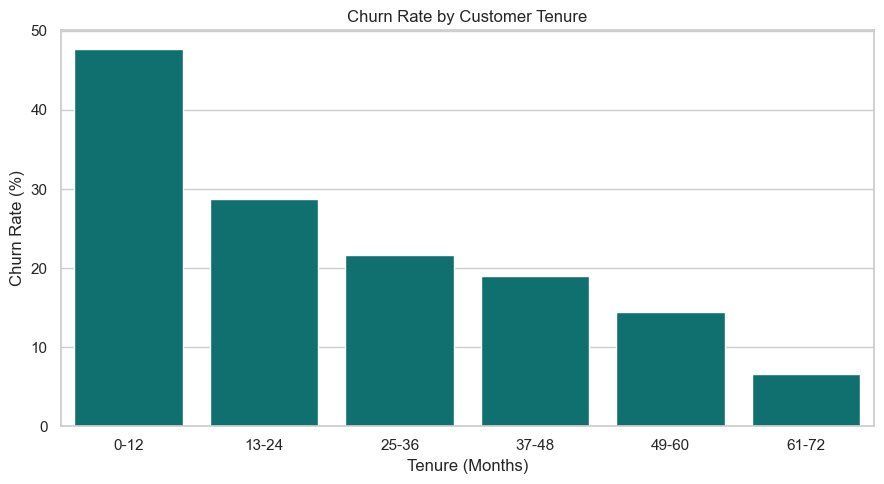

In [10]:
# ==================================================
# 8. CHURN ANALYSIS BY TENURE GROUP
# ==================================================

bins = [-1, 12, 24, 36, 48, 60, 72]
labels = ["0-12", "13-24", "25-36", "37-48", "49-60", "61-72"]

df["Tenure_Group"] = pd.cut(
    df["tenure"],
    bins=bins,
    labels=labels
)

tenure_churn = (
    df.groupby("Tenure_Group", observed=True)["Churn_Flag"]
    .mean()
    .mul(100)
    .reset_index(name="Churn_Rate")
)

print(tenure_churn.round(2))

plt.figure(figsize=(9, 5))

sns.barplot(
    data=tenure_churn,
    x="Tenure_Group",
    y="Churn_Rate",
    color="teal"
)

plt.title("Churn Rate by Customer Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

               PaymentMethod  Churn_Rate
0           Electronic check       45.29
1               Mailed check       19.20
2  Bank transfer (automatic)       16.73
3    Credit card (automatic)       15.25


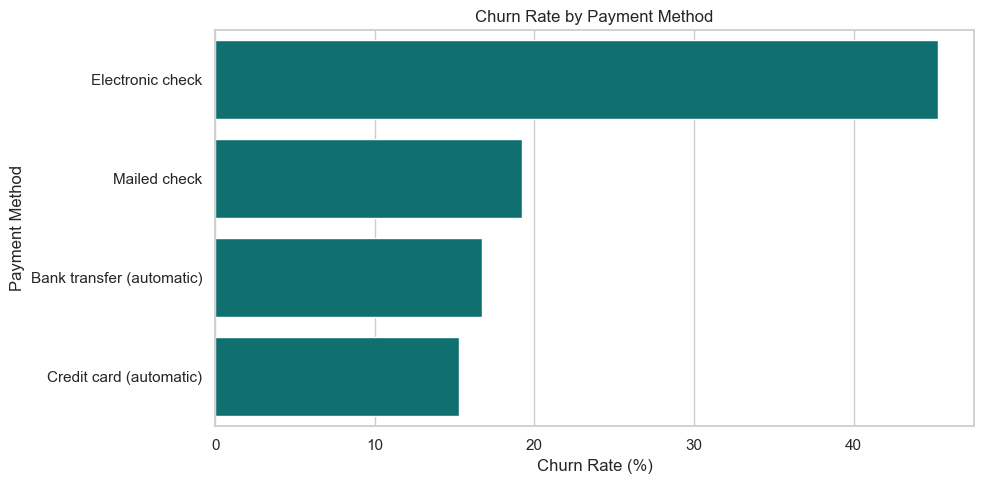

In [11]:
# ==================================================
# 9. CHURN ANALYSIS BY PAYMENT METHOD
# ==================================================

payment_churn = (
    df.groupby("PaymentMethod")["Churn_Flag"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .reset_index(name="Churn_Rate")
)

print(payment_churn.round(2))

plt.figure(figsize=(10, 5))

sns.barplot(
    data=payment_churn,
    x="Churn_Rate",
    y="PaymentMethod",
    color="teal"
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Churn Rate (%)")
plt.ylabel("Payment Method")
plt.tight_layout()
plt.show()

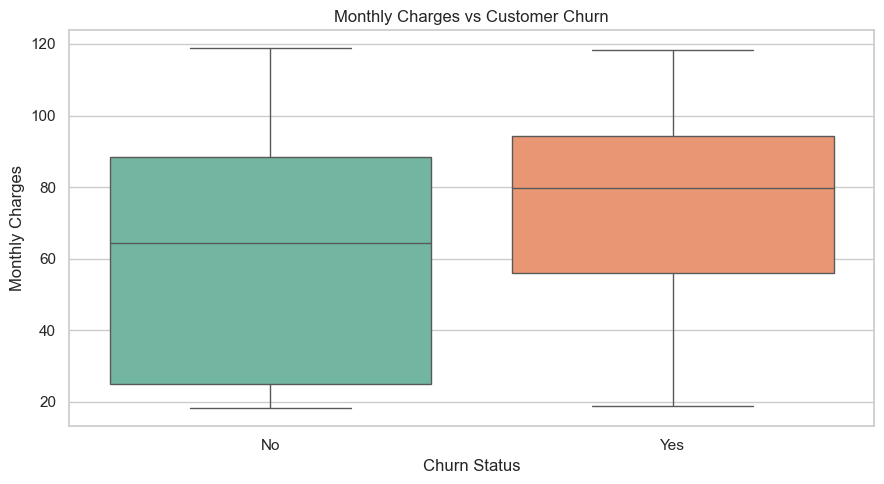

Churn
No     61.31
Yes    74.44
Name: MonthlyCharges, dtype: float64


In [12]:
# ==================================================
# 10. MONTHLY CHARGES AND CUSTOMER CHURN
# ==================================================

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

print(df.groupby("Churn")["MonthlyCharges"].mean().round(2))

In [13]:
# ==================================================
# 11. IDENTIFY HIGH-RISK CUSTOMER SEGMENTS
# ==================================================

high_risk = df[
    (df["InternetService"] == "Fiber optic") &
    (df["TechSupport"] == "No")
]

high_risk_rate = high_risk["Churn_Flag"].mean() * 100

print("Customers in Segment:", len(high_risk))
print(f"Segment Churn Rate: {high_risk_rate:.2f}%")
print(f"Overall Churn Rate: {churn_rate:.2f}%")

Customers in Segment: 2230
Segment Churn Rate: 49.37%
Overall Churn Rate: 26.58%


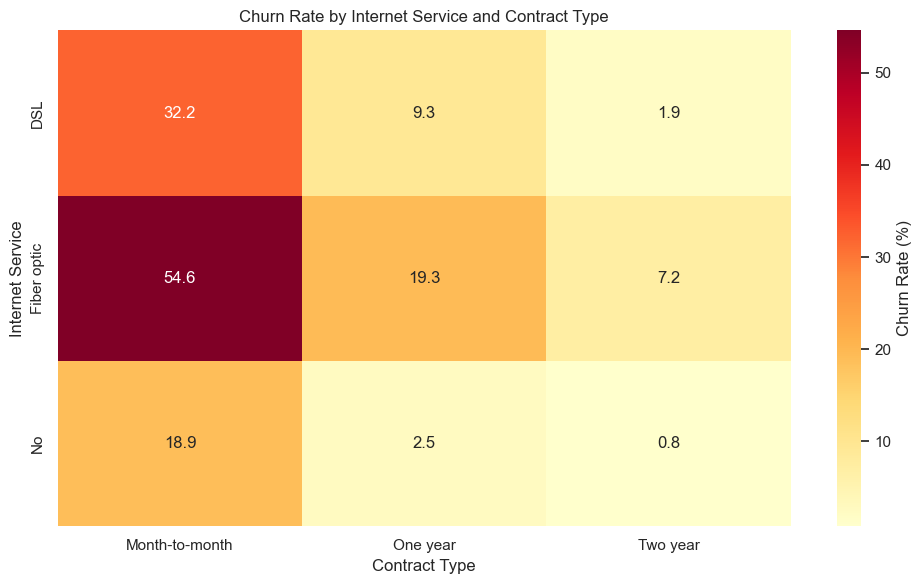

In [14]:
# ==================================================
# 12. CUSTOMER CHURN HEATMAP
# ==================================================

churn_heatmap = df.pivot_table(
    index="InternetService",
    columns="Contract",
    values="Churn_Flag",
    aggfunc="mean"
) * 100

plt.figure(figsize=(10, 6))

sns.heatmap(
    churn_heatmap,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    cbar_kws={"label": "Churn Rate (%)"}
)

plt.title("Churn Rate by Internet Service and Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Internet Service")
plt.tight_layout()
plt.show()

In [15]:
# ==================================================
# 13. CUSTOMER CHURN PREDICTION
# ==================================================

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score

features = [
    "tenure", "MonthlyCharges", "Contract",
    "PaymentMethod", "InternetService", "TechSupport"
]

X = df[features]
y = df["Churn_Flag"]

numeric_features = ["tenure", "MonthlyCharges"]

categorical_features = [
    "Contract", "PaymentMethod",
    "InternetService", "TechSupport"
]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, predictions))
print("ROC-AUC:", round(roc_auc_score(y_test, probabilities), 3))

              precision    recall  f1-score   support

           0       0.84      0.89      0.86      1033
           1       0.62      0.52      0.57       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.72      1407
weighted avg       0.78      0.79      0.78      1407

ROC-AUC: 0.831


In [16]:
# ==================================================
# 14. CUSTOMER CHURN PROBABILITIES
# ==================================================

results = X_test.copy()

results["Actual_Churn"] = y_test
results["Predicted_Churn"] = predictions
results["Churn_Probability"] = probabilities

results = results.sort_values(
    "Churn_Probability",
    ascending=False
)

results.head(10)

,tenure,MonthlyCharges,Contract,PaymentMethod,InternetService,TechSupport,Actual_Churn,Predicted_Churn,Churn_Probability
2246,1,102.45,Month-to-month,Electronic check,Fiber optic,No,1,1,0.777495
3380,1,95.10,Month-to-month,Electronic check,Fiber optic,No,1,1,0.765962
2797,3,100.95,Month-to-month,Electronic check,Fiber optic,No,1,1,0.764480
6240,1,93.30,Month-to-month,Electronic check,Fiber optic,No,1,1,0.763075
3727,3,96.60,Month-to-month,Electronic check,Fiber optic,No,1,1,0.757432
642,1,89.55,Month-to-month,Electronic check,Fiber optic,No,1,1,0.756982
1526,3,95.40,Month-to-month,Electronic check,Fiber optic,No,0,1,0.755462
3956,6,105.30,Month-to-month,Electronic check,Fiber optic,No,1,1,0.755028
2397,1,88.35,Month-to-month,Electronic check,Fiber optic,No,1,1,0.755010
1724,3,94.90,Month-to-month,Electronic check,Fiber optic,No,0,1,0.754638


In [17]:
# ==================================================
# 15. EXPORT ANALYSIS RESULTS
# ==================================================

df.to_csv("Telco_Churn_Cleaned.csv", index=False)
results.to_csv("Telco_Churn_Predictions.csv", index=False)

print("Files saved successfully!")


Files saved successfully!
